# 21 — Kiểm định contract 23 feature

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Golden vector đã chuẩn bị **không** có nghĩa parity Python/C hay triển khai ESP32 đã được kiểm chứng. Trạng thái: `PYTHON_REFERENCE_READY` · `C_PARITY_PENDING`.

**Mục tiêu.** Xác nhận rằng tên, thứ tự, cửa sổ, đơn vị và quy ước số học của 23 angle feature trong contract đề xuất khớp với **extractor Python production** (`ml/features/extractor.py`) — tham chiếu số học hiện hành mà mô hình RF đã được huấn luyện — và ghi lại mọi bất nhất thay vì tự giải quyết.

Notebook chỉ đọc: không sửa contract v0.1, không sửa công thức, không ghi file.

In [1]:
from pathlib import Path
import json, sys, hashlib, math, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/parity/golden.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/parity/golden.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from ml.parity.contract import (validate_contract, FEATURE_ORDER, EXPECTED_SELECTION, CONTRACT_V01, CONTRACT_V02,
                                feature_settings, run_extractor, schema_sha256)
validation = validate_contract(REPO_ROOT)
v02 = json.loads((REPO_ROOT / CONTRACT_V02).read_text(encoding="utf-8"))
settings = feature_settings(REPO_ROOT)
print("Số feature:", validation["feature_count"], "| schema:", validation["schema_version"])
print("SHA-256 thứ tự tên:", validation["schema_sha256"])
print("Khớp model card RF:", validation["model_card_schema_matches"], "| Bất nhất chặn:", validation["blocking_inconsistency"])

Số feature: 23 | schema: svmg-angle23-0.2.0-proposal
SHA-256 thứ tự tên: 060095dd1f6bf4264fdf1d95e601fe66880837cde08ec5896e35a67f7ff8a1c8
Khớp model card RF: True | Bất nhất chặn: False


## 1. Thứ tự feature trên mọi nguồn

Sáu nguồn độc lập trong repository phải liệt kê đúng cùng một thứ tự: danh sách kỳ vọng của milestone, `PRACTICAL_SUBSETS` của spec, `ANGLE_FEATURES` của workflow labeling, `FEATURE_ORDER` của RF, contract v0.1 và bảng trong tài liệu M1. Một lệch vị trí duy nhất làm RF nhận sai cột mà không báo lỗi.

In [2]:
orders = pd.DataFrame({"nguồn": list(validation["order_checks"]), "khớp_thứ_tự": list(validation["order_checks"].values())})
display(orders)
table = pd.DataFrame(v02["features"])[["index", "name", "group", "signal", "window_seconds", "unit", "definition"]]
display(table)
print("Đếm theo nhóm:", table.group.value_counts().sort_index().to_dict())

,nguồn,khớp_thứ_tự
0,milestone_expected_selection,True
1,ml.features.spec.PRACTICAL_SUBSETS,True
2,ml.labeling.human_review_workflow.ANGLE_FEATURES,True
3,ml.train.rf_poc.FEATURE_ORDER,True
4,feature_contract_23_v0.1.json,True
5,M2_23_Features_ESP32_Integration.md,True


,index,name,group,signal,window_seconds,unit,definition
0,0,roll_rms_60,A_roll_60,roll,60,deg,"sqrt(mean(x^2)) trên (t-60,t]"
1,1,roll_std_60,A_roll_60,roll,60,deg,độ lệch chuẩn quần thể (mẫu số n)
2,2,roll_mean_60,A_roll_60,roll,60,deg,mean(x)
3,3,roll_peak_to_peak_60,A_roll_60,roll,60,deg,max(x)-min(x)
4,4,roll_abs_p95_60,A_roll_60,roll,60,deg,phân vị Type-7 0.95 của |x|
5,5,roll_abs_max_60,A_roll_60,roll,60,deg,max(|x|)
6,6,roll_iqr_60,A_roll_60,roll,60,deg,Q0.75-Q0.25 Type-7
7,7,roll_diff_rms_60,A_roll_60,roll,60,deg/sample @10 Hz,RMS sai phân bậc 1 giữa mẫu kề đúng chu kỳ 0.1 s
8,8,roll_mean_180,C_roll_offset_180,roll,180,deg,mean(x)
9,9,roll_median_180,C_roll_offset_180,roll,180,deg,Q0.50 Type-7


Đếm theo nhóm: {'A_roll_60': 8, 'C_roll_offset_180': 6, 'D_roll_growth_180': 6, 'F_pitch_60': 3}


## 2. Quy ước số học

| Ký hiệu | Định nghĩa |
|---|---|
| Cửa sổ | mẫu i thuộc cửa sổ W tại endpoint t khi $t-W < t_i \le t$ (nửa mở); 10 Hz → 600/1800 mẫu |
| std | quần thể $\sqrt{\tfrac1n\sum (x_i-\bar x)^2}$ |
| Phân vị Type-7 | $h=(n-1)p,\; j=\lfloor h\rfloor,\; Q=z_j+(h-j)(z_{j+1}-z_j)$ |
| Sai phân | cặp kề nhau trong cửa sổ, cùng hữu hạn, cách đúng 0,1 s; 600 mẫu → **599** cặp |
| 3 block | $(t-180,t-120],(t-120,t-60],(t-60,t]$ |
| Slope | OLS trên $u=(30,90,150)$ s, ×60 → deg/phút; với 3 điểm cách đều $= (r_3-r_1)/2$ |
| R² | $1-SSE/SST$; UNDEFINED nếu $SST\le 10^{-15}$ |

In [3]:
config_checks = pd.Series(validation["config_checks"], name="giá trị")
for key in ("numeric_zero_epsilon_deg", "r_squared_zero_tolerance"):
    config_checks.loc[key] = f"{float(config_checks.loc[key]):.0e}"
display(config_checks.to_frame())
display(pd.Series(v02["coverage"], name="coverage").to_frame())
display(pd.DataFrame(validation["behaviour_checks"])[["id", "expected", "observed", "passed", "note"]])

,giá trị
sampling_hz_10,True
stride_10s,True
minimum_valid_fraction_0_95,True
maximum_gap_factor_1_5,True
quantile_type7,True
endpoint_convention,True
three_60s_blocks,True
numeric_zero_epsilon_deg,1e-09
r_squared_zero_tolerance,1e-15


,coverage
pointwise_minimum_finite_samples_60s,570
pointwise_minimum_finite_samples_180s,1710
diff_minimum_adjacent_pairs_60s,570
block_minimum_samples,570
maximum_gap_seconds,0.15
maximum_timestamps_in_window,N_expected + 1


,id,expected,observed,passed,note
0,population_std,0.707107,0.707107,True,"Sine biên độ 1, số chu kỳ nguyên: std quần thể = 1/sqrt(2); std mẫu (n-1) sẽ lớn hơn 0,083%."
1,type7_quantile,8.7802,8.7802,True,Cấp số cộng 600 giá trị: Q_0.95 Type-7 = x_min + 0.95*(n-1)*bước.
2,half_open_window,0.0,0.0,True,Mẫu tại đúng t-60 bị loại khỏi cửa sổ 60 s nhưng thuộc cửa sổ 180 s.
3,zero_signal_undefined,UNDEFINED_MATHEMATICALLY x3,"[UNDEFINED_MATHEMATICALLY, EARLY_RMS_AT_OR_BELOW_EPSILON, UNDEFINED_MATHEMATICALLY, CONSTANT_RMS_TREND, UNDEFINED_MA...",True,"Tín hiệu 0: ratio (rms_early <= epsilon), R² (SST = 0), sign ratio (không có mẫu khác 0) đều không xác định, không b..."
4,warmup,"60 s VALID, 180 s INSUFFICIENT_WINDOW","[VALID, INSUFFICIENT_WINDOW, WINDOW_HISTORY_SHORT]",True,150 s lịch sử: feature 180 s chưa được tính (WARMUP).
5,trend_slope_units,0.707107,0.707107,True,"RMS block 1/√2, 2/√2, 3/√2 tại tâm 30/90/150 s: slope = (r3-r1)/120 s × 60 = deg/phút."
6,difference_pair_semantics,"rms VALID, diff_rms INVALID_INPUT/ADJACENT_PAIR_COVERAGE","[VALID, INVALID_INPUT, ADJACENT_PAIR_COVERAGE]",True,"20 NaN rời rạc (3,3%) giữ feature pointwise hợp lệ nhưng xóa 40 cặp kề nhau: 559 < 570 cặp."


## 3. Minh họa ranh giới cửa sổ nửa mở

Đặt một gai +10° tại đúng $t=150$ s rồi tính tại endpoint 200 s và 210 s. Với $(t-60,t]$: tại 210 s, mẫu $t=150$ **không** thuộc cửa sổ 60 s nhưng thuộc cửa sổ 180 s.

,endpoint,roll_abs_max_60,roll_mean_180
13,190.0,10.0,0.005556
14,200.0,10.0,0.005556
15,210.0,0.0,0.005556


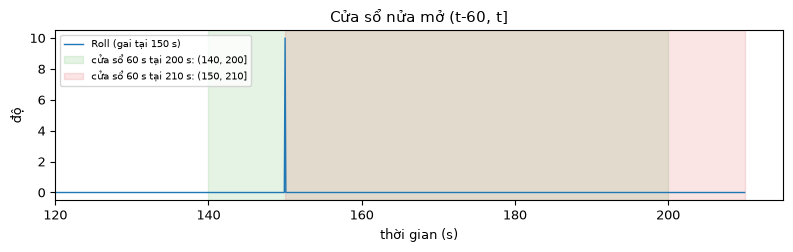

In [4]:
t = np.arange(2101) / 10.0
x = np.zeros_like(t); x[1500] = 10.0
values, meta, _ = run_extractor(t, x, np.zeros_like(t), settings)
show = values.assign(endpoint=meta.window_end_seconds.values)[["endpoint", "roll_abs_max_60", "roll_mean_180"]].tail(3)
display(show)
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(t, x, lw=1, label="Roll (gai tại 150 s)")
for end, color in ((200, "tab:green"), (210, "tab:red")):
    ax.axvspan(end - 60, end, alpha=0.12, color=color, label=f"cửa sổ 60 s tại {end} s: ({end-60}, {end}]")
ax.set_xlim(120, 215); ax.set_xlabel("thời gian (s)"); ax.set_ylabel("độ"); ax.legend(fontsize=7); ax.set_title("Cửa sổ nửa mở (t-60, t]")
plt.tight_layout(); plt.show()

## 4. Bất nhất và điểm cần làm rõ

Các mục `MATERIAL` là chỗ chữ của đặc tả và hành vi đã hiện thực khác nhau, hoặc tham số chưa được nhóm chốt. Golden đi theo extractor; không có mục nào được giải quyết ngầm.

In [5]:
issues = pd.DataFrame(validation["issues"])
display(issues[["id", "severity", "status", "title", "golden_policy"]])

,id,severity,status,title,golden_policy
0,C01,MATERIAL,OPEN_TEAM_DECISION,Điều kiện hợp lệ của feature block 180 s,Golden theo extractor (tham chiếu số học). Hiện thực C theo đúng chữ của đặc tả sẽ lệch validity ở cửa sổ thiếu mẫu.
1,C02,MATERIAL,OPEN_TEAM_DECISION,Epsilon mẫu số của roll_rms_ratio_180,Golden dùng 1e-9 deg; case sát epsilon được đánh dấu ILL_CONDITIONED.
2,C03,MATERIAL,OPEN_TEAM_DECISION,Ngưỡng SST của roll_rms_trend_r2_180 thấp hơn độ phân giải float32,Golden giữ quyết định của extractor; harness xếp R² có SST tương đối nhỏ vào REVIEW_ILL_CONDITIONED thay vì PASS/FAI...
3,C04,MATERIAL,OPEN_TEAM_DECISION,Biểu diễn mẫu thiếu: NaN có timestamp khác với timestamp bị bỏ,Golden có cả hai trường hợp. M1 phải chọn cách biểu diễn mẫu lỗi khớp với ý định (khuyến nghị: giữ nhịp 10 Hz và ghi...
4,C05,CLARIFICATION,DOCUMENTED_IN_V0_2,Neo lưới endpoint,Golden ghi rõ endpoint (chỉ số và thời gian) cho từng case; C đánh giá đúng tại các endpoint đó.
5,C06,CLARIFICATION,DOCUMENTED_IN_V0_2,roll_rms_late_60 trùng giá trị nhưng khác validity với roll_rms_60,NaN
6,C08,CLARIFICATION,DOCUMENTED_IN_V0_2,Mã lý do của roll_dominant_sign_ratio_180 khi mọi mẫu bằng 0,Status được so khớp bắt buộc; reason_code chỉ so như cảnh báo. M1 nên xuất NON_FINITE_RESULT để trùng golden.
7,C09,CLARIFICATION,DOCUMENTED_IN_V0_2,Chỉ số 0-based của contract và STT 1-based trong tài liệu M1,Interchange dùng feature_index 0-based; harness kiểm tra feature_name khớp index để bắt lệch 1 vị trí.
8,C07,MATERIAL,SUPERSEDED_IN_V0_2,Dung sai parity một giá trị chung trong v0.1,v0.2 thay bằng dung sai theo nhóm feature có hạng tỷ lệ theo biên độ đầu vào (ml/parity/fixtures/tolerance_spec.json).


## 5. Minh họa issue C01 — quy tắc hợp lệ của feature block

Thiếu 40 mẫu ở **block đầu** của cửa sổ 180 s: theo chữ đặc tả, `roll_rms_late_60` chỉ cần block cuối nên vẫn hợp lệ; theo extractor, cả 8 feature block bị INVALID.

In [6]:
x = 2 * np.sin(2 * np.pi * 0.1 * t + 0.3); x[500:540] = np.nan
values, meta, _ = run_extractor(t, x, np.zeros_like(t), settings)
validity = json.loads(meta.iloc[-1].validity_json)
display(pd.DataFrame({f: {"status": validity[f]["status"], "reason": validity[f]["reason_code"], "value": values.iloc[-1][f]}
                      for f in ("roll_rms_60", "roll_mean_180", "roll_rms_early_60", "roll_rms_late_60")}).T)

,status,reason,value
roll_rms_60,VALID,None,1.414214
roll_mean_180,VALID,None,-0.034371
roll_rms_early_60,INVALID_INPUT,SEGMENT_BLOCK_COVERAGE,NaN
roll_rms_late_60,INVALID_INPUT,SEGMENT_BLOCK_COVERAGE,NaN


## Diễn giải

- Thứ tự và cửa sổ của 23 feature **nhất quán** trên cả 6 nguồn; SHA-256 schema trùng model card RF, nên được phép sinh golden.
- Mọi quy ước được yêu cầu (10 Hz, độ, 60/180 s, stride 10 s, std quần thể, Type-7, sai phân 599 cặp, 3 block, slope deg/phút, epsilon, R², missing/gap, warm-up) đã được kiểm bằng hành vi thực của extractor chứ không chỉ đọc tài liệu.
- Bốn vấn đề còn mở (C01–C04) cần M1/M2 quyết định; khi thay đổi phải tăng phiên bản contract, sinh lại golden và có thể phải huấn luyện lại RF.

## Hạn chế

- Kiểm định này so sánh các *mô tả* và *hành vi* trong repository; nó không chứng minh các quy ước là tối ưu về vật lý (ví dụ epsilon 1e-9 deg là số học, không theo nhiễu cảm biến).
- Contract C 14 trường hiện hành không bị chạm tới; vector 23 feature vẫn là `PROPOSAL_PENDING_M1_REVIEW`.

## Ghi chú vấn đáp

- *Vì sao lấy extractor làm chuẩn?* Vì RF học trên chính các số đó; một cách hiểu khác của tài liệu sẽ tạo lệch phân phối dù "đúng chữ".
- *Một lệch thứ tự được phát hiện thế nào?* So 6 danh sách tên + băm SHA-256 thứ tự; harness parity còn kiểm `feature_name` khớp `feature_index` cho từng bản ghi.
- *C01 ảnh hưởng gì đến firmware?* Nếu M1 hiện thực theo chữ đặc tả, validity của `rms_late`/`rms_early`/`mean_shift` sẽ khác golden ở cửa sổ thiếu mẫu (case SYN27).